# 메타팩토리 불량 원인 분석 — DoWhy · PyRCA

앱 **품질 추적 → ⬇ 전체 데이터셋 (.zip)**(또는 사례 하나 .zip)으로 내려받은 RCA 데이터로 불량 원인을 두 가지 오픈소스 방법으로 분석하고, 앱 내장 분석(계보 베이즈 분해)과 비교합니다.

| 단계 | 도구 | 질문 |
|---|---|---|
| ① 제품 단위 | **DoWhy GCM** (MIT) — 그래프 인과 모델 · 이상 원인 분해 `attribute_anomalies` | 이 NG 제품은 **어느 셀·어떤 요인** 때문에 규격을 벗어났나? |
| ② 시간 구간 단위 | **PyRCA** (BSD-3) — 가설검정(HT) · 랜덤 워크 · ε-Diagnosis | 불량이 늘어난 구간에 **어떤 지표가 먼저 변했나?** |
| ③ 검증 | `features.csv`의 `label_root_cause_station`(시뮬레이션 정답) | 각 방법의 Top-1 · Top-3 적중률 |

**설치** (Python 3.10~3.11 권장)
```bash
pip install -r requirements.txt
pip install --no-deps sfr-pyrca==1.0.1   # javabridge(Java 빌드) 의존성을 빼고 설치
```


## 0. 데이터 불러오기
`DATA`에 내려받은 .zip 또는 압축을 푼 폴더를 지정합니다. 비워 두면 이 폴더와 `~/Downloads`에서 가장 최근 `RCA_dataset_*.zip`을 찾습니다.

In [1]:
import os, glob, json, zipfile, tempfile, warnings
from pathlib import Path
import numpy as np, pandas as pd, networkx as nx
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
from matplotlib import font_manager
plt.rcParams['font.family'] = [f for f in ('AppleGothic', 'Malgun Gothic', 'NanumGothic') if f in {x.name for x in font_manager.fontManager.ttflist}][:1] or ['DejaVu Sans']   # 한글 글꼴 (설치된 것 하나)
plt.rcParams['axes.unicode_minus'] = False

DATA = os.environ.get('RCA_DATA', '')   # 예: '~/Downloads/RCA_dataset_904products_18cases_xxx.zip'

def find_data(p):
    if p: return Path(p).expanduser()
    hits = sorted([*glob.glob('RCA_dataset_*.zip'), *glob.glob(os.path.expanduser('~/Downloads/RCA_dataset_*.zip'))], key=os.path.getmtime)
    if not hits: raise FileNotFoundError('RCA 데이터(.zip 또는 폴더)를 DATA에 지정하세요 — 앱 품질 추적 창 ⬇ 전체 데이터셋')
    return Path(hits[-1])

src = find_data(DATA)
if src.suffix == '.zip':
    root = Path(tempfile.mkdtemp(prefix='rca_')); zipfile.ZipFile(src).extractall(root)
else:
    root = src
print('데이터:', src.name)
manifest = json.loads((root / 'manifest.json').read_text())
features = pd.read_csv(root / 'features.csv')
env = pd.read_csv(root / 'environment.csv')
graph_spec = json.loads((root / 'causal_graph.json').read_text())
cases = json.loads((root / 'cases.json').read_text()) if (root / 'cases.json').exists() else [json.loads((root / 'case.json').read_text())]
features = features[features.status != 'wip'].copy()
print(manifest.get('schema'), '· 제품', len(features), '· 불량 사례', len(cases), '· 공장 모드', features['mode'].iloc[0])

데이터: rcads
meta-factory/rca-dataset/1.0 · 제품 896 · 불량 사례 18 · 공장 모드 smart


## 1. 데이터 개요
`label_ng` = 불량(검출 NG + 유출), `label_root_cause_station` = 불량이 실제로 생긴 셀(시뮬레이션 정답 — 실제 공장에는 없는 값이라 **평가에만** 씁니다).

In [2]:
summary = features.groupby('product').agg(제품=('serial', 'size'), 불량=('label_ng', 'sum'))
summary['불량률(%)'] = (summary['불량'] / summary['제품'] * 100).round(2)
display(summary)
display(features.loc[features.label_ng == 1, ['serial', 'product', 'status', 'label_root_cause_station', 'inspect_torque', 'inspect_angle']].head(20))
print('정답 원인 셀 분포:', features.label_root_cause_station.value_counts().to_dict())

,제품,불량,불량률(%)
product,,,
doortrim,449,11,2.45
eaxle,447,8,1.79


,serial,product,status,label_root_cause_station,inspect_torque,inspect_angle
86,DT-261018-000044,doortrim,ng,SORT,4.58,44.7
127,EA-261018-000064,eaxle,ng,EA_ASSY,75.47,43.4
174,DT-261018-000088,doortrim,ng,DT_ASSY,3.71,27.9
226,DT-261018-000114,doortrim,ng,DT_ASSY,3.83,32.1
233,EA-261018-000117,eaxle,ng,EA_ASSY,73.49,50.3
258,DT-261018-000130,doortrim,ng,SORT,4.66,43.0
292,DT-261018-000147,doortrim,ng,DT_ASSY,3.77,32.5
338,DT-261018-000170,doortrim,ng,SORT,4.60,46.6
341,EA-261018-000171,eaxle,ng,SORT,83.21,66.9
406,DT-261018-000204,doortrim,ng,DT_ASSY,3.87,31.7


정답 원인 셀 분포: {'SORT': 7, 'DT_ASSY': 7, 'EA_ASSY': 4}


### 공정 측정값 — 불량 vs 양품
불량이 생긴 셀은 그 셀의 공정 측정값(부품 인식 점수 · 압입 하중 · 안착 깊이)에 흔적을 남깁니다. 아래 표는 열마다 양품 평균 대비 불량 평균의 차이(표준편차 단위)입니다.

In [3]:
PARAMS = [c for c in features.columns if c.split('_')[-1] in ('visionScore', 'pickForce', 'pressForce', 'seatDepth')]
STATE = [c for c in features.columns if c.endswith(('_health', '_drift'))]
def effect(cols):
    ok, ng = features[features.label_ng == 0], features[features.label_ng == 1]
    return pd.DataFrame({'양품 평균': ok[cols].mean(), '불량 평균': ng[cols].mean(), '차이(σ)': (ng[cols].mean() - ok[cols].mean()) / ok[cols].std()}).round(3).sort_values('차이(σ)', key=abs, ascending=False)
display(effect(PARAMS + STATE).head(12))

,양품 평균,불량 평균,차이(σ)
EA_ASSY_pressForce,2.804,2.334,-3.180
DT_ASSY_pressForce,2.805,2.305,-3.140
SORT_visionScore,0.969,0.914,-2.665
DT_ASSY_seatDepth,12.012,12.295,2.551
EA_ASSY_seatDepth,12.007,12.200,1.792
EA_ASSY_drift,0.139,0.208,0.778
PACK_health,72.369,78.100,0.422
SORT_drift,0.144,0.178,0.382
PACK_drift,0.152,0.117,-0.374
DT_ASSY_health,76.674,81.536,0.333


## 2. DoWhy GCM — NG 제품별 이상 원인 분해

### 2-1. 인과 그래프
앱의 `causal_graph.json`은 셀 하나의 구조(환경·설비 상태 → 불량(잠재) → 공정 측정값 → 검사 토크·각도)입니다. 제품 라인마다 이를 **셀별로 펼쳐** 씁니다.

- 뿌리 노드: 셀마다 건강도 · 드리프트 · 그 공정이 민감한 환경값 (앱 `ENV_SENS`: 도어트림 조립 = 습도·진동, e-axle 조립 = 온도·진동, 부품분류 = 미세먼지·조도)
- 중간 노드: 그 셀의 공정 측정값 (잠재 변수 `defect`가 여기에 드러남)
- 목표 노드 `qdev`: 체결셀 검사 토크·각도의 규격 이탈 정도 = max(|토크 − 중앙| / 반폭, |각도 − 중앙| / 반폭) — **1을 넘으면 NG**

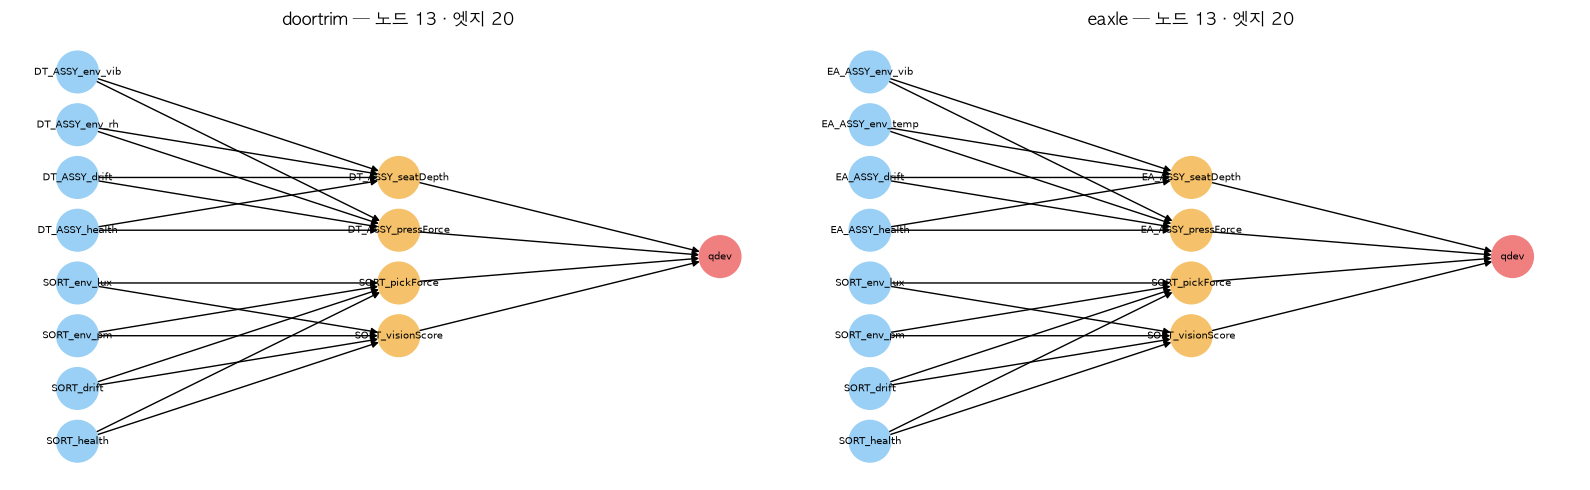

In [4]:
from dowhy import gcm
from dowhy.gcm.util.general import set_random_seed
gcm.config.disable_progress_bars(); set_random_seed(0)   # 메커니즘 선택·샤플리 표본 재현

LINES = {'doortrim': {'cells': ['SORT', 'DT_ASSY'], 'insp': 'DT_FAST', 'spec': {'torque': (4.0, 5.0), 'angle': (20, 40)}},
         'eaxle':    {'cells': ['SORT', 'EA_ASSY'], 'insp': 'EA_FAST', 'spec': {'torque': (78, 92), 'angle': (30, 60)}}}
SENS = {'SORT': ['pm', 'lux'], 'DT_ASSY': ['rh', 'vib'], 'EA_ASSY': ['temp', 'vib']}
FACTOR = {'health': '설비 열화(건강도)', 'drift': '공정 드리프트', 'env': '환경', 'param': '공정 측정값 이탈(그 셀 작업 불량)'}

def qdev(d, spec):
    (tl, tu), (al, au) = spec['torque'], spec['angle']
    return np.maximum((d.inspect_torque - (tl + tu) / 2).abs() / ((tu - tl) / 2), (d.inspect_angle - (al + au) / 2).abs() / ((au - al) / 2))

def build_graph(d, cells):
    G = nx.DiGraph()
    for c in cells:
        roots = [f'{c}_health', f'{c}_drift'] + [f'{c}_env_{k}' for k in SENS.get(c, [])]
        params = [p for p in PARAMS if p.startswith(c + '_')]
        for p in params:
            for r in roots: G.add_edge(r, p)
            G.add_edge(p, 'qdev')
    return G

CELLS = ['DT_ASSY', 'EA_ASSY', 'DT_FAST', 'EA_FAST', 'SORT', 'PACK']
def cell_of(node): return next((c for c in CELLS if node.startswith(c + '_')), node)
def factor_of(node):   # 노드 이름 '셀_항목' → 요인
    tail = node[len(cell_of(node)) + 1:]
    return 'env' if tail.startswith('env_') else tail if tail in ('health', 'drift') else 'param'

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
graphs = {}
for ax, (prod, L) in zip(axes, LINES.items()):
    d = features[features['product'] == prod]
    G = graphs[prod] = build_graph(d, L['cells'])
    pos = nx.multipartite_layout(G, subset_key={0: [n for n in G if G.in_degree(n) == 0], 1: [n for n in G if G.in_degree(n) and n != 'qdev'], 2: ['qdev']})
    nx.draw_networkx(G, pos, ax=ax, node_size=900, font_size=7, node_color=['#9ad0f5' if G.in_degree(n) == 0 else '#f5c26b' if n != 'qdev' else '#f08080' for n in G], arrowsize=10)
    ax.set_title(f'{prod} — 노드 {G.number_of_nodes()} · 엣지 {G.number_of_edges()}'); ax.axis('off')
plt.tight_layout(); plt.show()

### 2-2. 학습 · NG 제품마다 원인 분해
각 노드의 인과 메커니즘을 자동 선택(`auto.assign_causal_mechanisms`)해 학습하고, NG 제품마다 `attribute_anomalies`로 `qdev` 이상을 노드별 기여(샤플리 값)로 나눕니다. 노드 기여를 셀별로 합해 **원인 셀 순위**를, 요인별로 합해 **원인 요인**을 냅니다.

In [5]:
app_top = {c['serial']: (c.get('rca') or {}).get('top', {}) for c in cases if c.get('kind', 'inline') == 'inline'}
app_rank = {c['serial']: [s['id'] for s in (c.get('rca') or {}).get('stations', [])] for c in cases}
rows, contrib = [], []
for prod, L in LINES.items():
    d = features[features['product'] == prod].copy(); d['qdev'] = qdev(d, L['spec'])
    G = graphs[prod]; X = d[list(G.nodes)].dropna().astype(float)
    scm = gcm.InvertibleStructuralCausalModel(G)
    gcm.auto.assign_causal_mechanisms(scm, X, quality=gcm.auto.AssignmentQuality.GOOD)
    gcm.fit(scm, X)
    for i, r in d[(d.label_ng == 1) & d.index.isin(X.index)].iterrows():
        a = {n: float(v[0]) for n, v in gcm.attribute_anomalies(scm, 'qdev', anomaly_samples=X.loc[[i]]).items()}
        by_cell = {c: sum(max(0, v) for n, v in a.items() if n.startswith(c + '_')) for c in L['cells']}
        rank = sorted(by_cell, key=by_cell.get, reverse=True)
        top_node = max((n for n in a if n != 'qdev'), key=a.get)
        rows.append({'serial': r.serial, 'product': prod, '정답 셀': r.label_root_cause_station, 'DoWhy 1순위 셀': rank[0], 'DoWhy 순위': rank,
                     'DoWhy 요인': FACTOR[factor_of(top_node)], '기여 1위 노드': top_node, '셀 기여': {k: round(v, 2) for k, v in by_cell.items()},
                     '앱 1순위 셀': app_top.get(r.serial, {}).get('station'), '앱 요인': app_top.get(r.serial, {}).get('label')})
        contrib += [{'serial': r.serial, 'product': prod, 'node': n, 'cell': cell_of(n), 'factor': factor_of(n), 'contribution': v} for n, v in a.items() if n != 'qdev']
res = pd.DataFrame(rows); contrib = pd.DataFrame(contrib)
display(res.drop(columns=['DoWhy 순위']))

,serial,product,정답 셀,DoWhy 1순위 셀,DoWhy 요인,기여 1위 노드,셀 기여,앱 1순위 셀,앱 요인
0,DT-261018-000044,doortrim,SORT,SORT,공정 측정값 이탈(그 셀 작업 불량),SORT_visionScore,"{'SORT': 4.74, 'DT_ASSY': 0.01}",SORT,부품분류셀 · 설비 열화 (건강도 저하)
1,DT-261018-000088,doortrim,DT_ASSY,DT_ASSY,공정 측정값 이탈(그 셀 작업 불량),DT_ASSY_pressForce,"{'SORT': 0.4, 'DT_ASSY': 5.88}",DT_ASSY,도어트림 조립셀 · 공정 고유 산포
2,DT-261018-000114,doortrim,DT_ASSY,DT_ASSY,공정 측정값 이탈(그 셀 작업 불량),DT_ASSY_pressForce,"{'SORT': 0.19, 'DT_ASSY': 6.25}",DT_ASSY,도어트림 조립셀 · 공정 드리프트 (재보정 필요)
3,DT-261018-000130,doortrim,SORT,SORT,공정 측정값 이탈(그 셀 작업 불량),SORT_visionScore,"{'SORT': 2.57, 'DT_ASSY': 0.24}",SORT,부품분류셀 · 공정 드리프트 (재보정 필요)
4,DT-261018-000147,doortrim,DT_ASSY,DT_ASSY,공정 측정값 이탈(그 셀 작업 불량),DT_ASSY_seatDepth,"{'SORT': 0.02, 'DT_ASSY': 5.61}",DT_ASSY,도어트림 조립셀 · 설비 열화 (건강도 저하)
5,DT-261018-000170,doortrim,SORT,SORT,공정 측정값 이탈(그 셀 작업 불량),SORT_visionScore,"{'SORT': 6.39, 'DT_ASSY': 0.06}",SORT,부품분류셀 · 설비 열화 (건강도 저하)
6,DT-261018-000204,doortrim,DT_ASSY,DT_ASSY,공정 측정값 이탈(그 셀 작업 불량),DT_ASSY_pressForce,"{'SORT': 0.22, 'DT_ASSY': 6.13}",DT_ASSY,도어트림 조립셀 · 공정 고유 산포
7,DT-261018-000233,doortrim,DT_ASSY,DT_ASSY,공정 측정값 이탈(그 셀 작업 불량),DT_ASSY_seatDepth,"{'SORT': 0.22, 'DT_ASSY': 5.67}",NaN,AM-12 · 운반 AMR
8,DT-261018-000303,doortrim,DT_ASSY,DT_ASSY,공정 측정값 이탈(그 셀 작업 불량),DT_ASSY_pressForce,"{'SORT': 0.03, 'DT_ASSY': 4.64}",DT_ASSY,도어트림 조립셀 · 설비 열화 (건강도 저하)
9,DT-261018-000341,doortrim,DT_ASSY,DT_ASSY,공정 측정값 이탈(그 셀 작업 불량),DT_ASSY_seatDepth,"{'SORT': 0.6, 'DT_ASSY': 5.7}",DT_ASSY,도어트림 조립셀 · 설비 열화 (건강도 저하)


### 2-3. 적중률 — DoWhy vs 앱 내장 분석
정답이 있는 사례(검출 NG)만 셉니다. 정밀검사Zone 샘플 NG 사례는 정답 라벨이 없어 뺍니다.

In [6]:
ev = res[res['정답 셀'].notna()]
def hit(rank_col, truth, k): return sum(t in (r[:k] if isinstance(r, list) else [r]) for r, t in zip(ev[rank_col], truth))
app_ev = ev[ev['앱 1순위 셀'].notna()]
score = pd.DataFrame({
    '사례': [len(ev), len(app_ev)],
    'Top-1': [hit('DoWhy 순위', ev['정답 셀'], 1), sum(app_ev['앱 1순위 셀'] == app_ev['정답 셀'])],
    'Top-2': [hit('DoWhy 순위', ev['정답 셀'], 2), sum(t in app_rank.get(s, [])[:2] for s, t in zip(app_ev.serial, app_ev['정답 셀']))],
}, index=['DoWhy GCM', '앱 내장 (계보 베이즈 분해)'])
score['Top-1 적중률'] = (score['Top-1'] / score['사례']).map('{:.0%}'.format)
display(score)

,사례,Top-1,Top-2,Top-1 적중률
DoWhy GCM,18,17,18,94%
앱 내장 (계보 베이즈 분해),17,17,17,100%


### 2-4. 사례 하나 자세히 — 노드별 기여

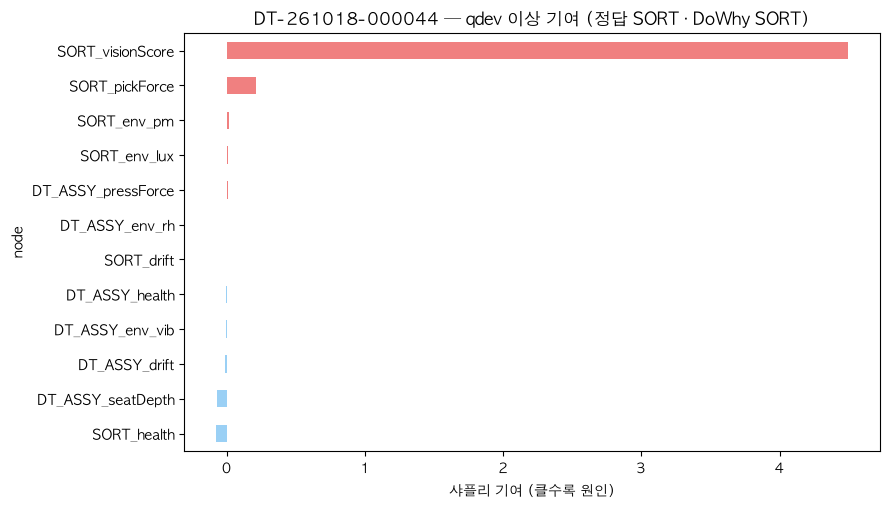

In [7]:
if len(res):
    s = res.iloc[0].serial
    one = contrib[contrib.serial == s].sort_values('contribution')
    ax = one.plot.barh(x='node', y='contribution', figsize=(9, 0.35 * len(one) + 1), legend=False, color=['#f08080' if v > 0 else '#9ad0f5' for v in one.contribution])
    ax.set_title(f'{s} — qdev 이상 기여 (정답 {res.iloc[0]["정답 셀"]} · DoWhy {res.iloc[0]["DoWhy 1순위 셀"]})'); ax.set_xlabel('샤플리 기여 (클수록 원인)'); plt.tight_layout(); plt.show()

### 2-5. 전체 불량 — 셀 · 요인별 기여 합
8D D5(대책 선정)의 근거: 불량 전체에서 어느 셀·어떤 요인이 반복되는지. `공정 측정값 이탈`이 크면 그 셀의 작업 자체(지그·그리퍼·압입 조건), `설비 열화`·`드리프트`가 크면 예지정비·재보정 기준, `환경`이 크면 환경 인터록이 대책 후보입니다.

factor,공정 드리프트,환경,설비 열화(건강도),공정 측정값 이탈(그 셀 작업 불량)
cell,,,,
DT_ASSY,1.32,3.05,0.77,35.16
EA_ASSY,0.84,2.25,0.46,23.78
SORT,2.88,1.08,0.47,29.43


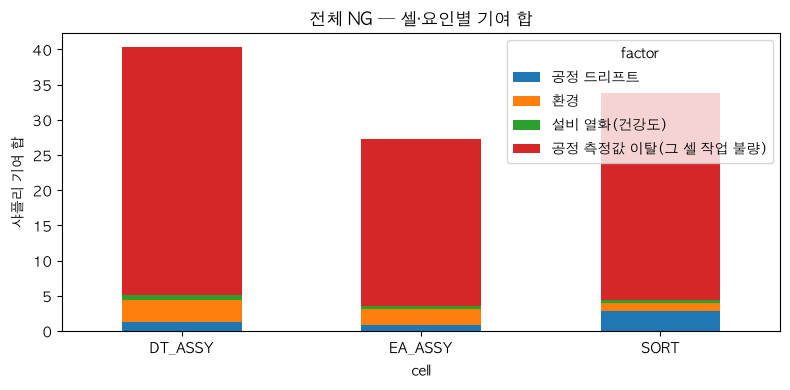

In [8]:
pos = contrib[contrib.contribution > 0]
pivot = pos.pivot_table(index='cell', columns='factor', values='contribution', aggfunc='sum', fill_value=0).rename(columns=FACTOR)
display(pivot.round(2))
pivot.plot.bar(stacked=True, figsize=(8, 4), title='전체 NG — 셀·요인별 기여 합'); plt.ylabel('샤플리 기여 합'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 3. PyRCA — 불량이 늘어난 시간 구간의 근본 원인

DoWhy는 제품 한 개를 봤다면, PyRCA는 **지표 시계열**에서 이상 구간의 근본 원인을 찾습니다(원래 IT 운영 지표용 도구 — 여기서는 공정 지표에 적용).

### 3-1. 시계열 만들기
제품을 투입 시각 기준 `BIN`초 구간으로 묶어 셀별 건강도 · 드리프트 · 공정 측정값 평균, 그 셀 환경값(`environment.csv` 센서), 불량 수(`ng_count`)를 만듭니다.

구간 48개 (300초) · 정상 32 · 불량 발생 16


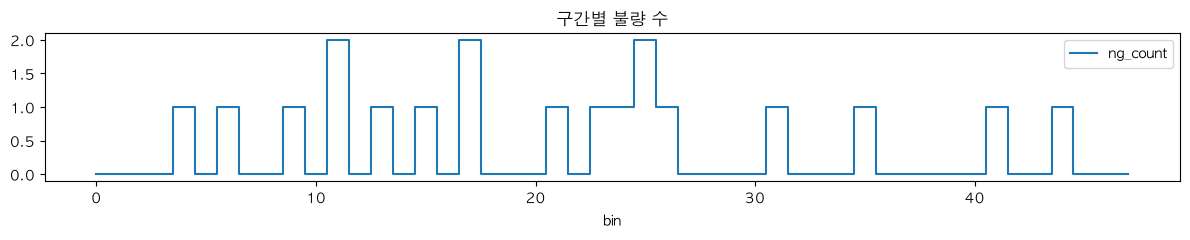

In [9]:
BIN = 300   # 초 — 데이터가 길면 줄이고(120), 짧으면 늘린다
NODE_OF = {'SORT': 'ENV-01', 'DT_ASSY': 'ENV-02', 'EA_ASSY': 'ENV-03'}   # 셀 ↔ 환경 센서 (앱 ENV_NODES)
f = features.assign(bin=(features.t_release_s // BIN).astype(int))
agg = {f'{c}_{k}': 'mean' for c in SENS for k in ('health', 'drift')}
agg.update({p: 'mean' for p in PARAMS if p.split('_')[-1] != 'pickForce'})
ts = f.groupby('bin').agg({**agg, 'label_ng': 'sum'}).rename(columns={'label_ng': 'ng_count'})
e = env.assign(bin=(env.t_s // BIN).astype(int)).groupby('bin').mean(numeric_only=True)
for c, ks in SENS.items():
    for k in ks: ts[f'{c}_env_{k}'] = e[f'{NODE_OF[c]}_{k}'].reindex(ts.index)
ts = ts.interpolate().bfill().ffill()
const = [c for c in ts.columns if c != 'ng_count' and ts[c].std() < 1e-9]   # 변하지 않는 지표(예: 드리프트 0)는 상관·회귀가 정의되지 않아 뺀다
ts = ts.drop(columns=const)
if const: print('변화 없는 지표 제외:', const)
normal, abnormal = ts[ts.ng_count == 0], ts[ts.ng_count > 0]
print(f'구간 {len(ts)}개 ({BIN}초) · 정상 {len(normal)} · 불량 발생 {len(abnormal)}')
ax = ts[['ng_count']].plot(figsize=(12, 2.5), drawstyle='steps-mid', title='구간별 불량 수'); plt.tight_layout(); plt.show()

### 3-2. 인과 그래프 — 도메인 그래프 vs PC 학습
PyRCA 분석기(HT · 랜덤 워크)는 그래프가 필요합니다. 구간 수가 적으면 PC 학습 그래프가 빈약하므로 기본은 **앱 인과 그래프를 셀별로 펼친 도메인 그래프**(건강도·드리프트·환경 → 공정 측정값 → 불량 수)이고, PC 결과는 비교용으로 함께 봅니다.

In [10]:
import logging; logging.getLogger().setLevel(logging.ERROR)
from pyrca.graphs.causal.pc import PC
nodes = list(ts.columns)
dom = pd.DataFrame(0, index=nodes, columns=nodes)   # dom.loc[부모, 자식] = 1
for c in SENS:
    roots = [n for n in nodes if n.startswith(c + '_') and n.split(c + '_')[1] in ['health', 'drift', *[f'env_{k}' for k in SENS[c]]]]
    for p in [n for n in nodes if n.startswith(c + '_') and n in PARAMS]:
        dom.loc[roots, p] = 1; dom.loc[p, 'ng_count'] = 1
pc = PC(PC.config_class()).train(normal.assign(ng_count=normal.ng_count + np.random.default_rng(0).normal(0, 1e-3, len(normal))))
print('도메인 그래프 엣지', int(dom.values.sum()), '· PC 학습 엣지', int(pc.values.sum()), '(정상 구간', len(normal), '개로 학습)')

  0%|          | 0/18 [00:00<?, ?it/s]

  0%|          | 0/18 [00:00<?, ?it/s]

Depth=0, working on node 0:   6%|▌         | 1/18 [00:00<00:00, 4788.02it/s]

Depth=0, working on node 1:  11%|█         | 2/18 [00:00<00:00, 1286.20it/s]

Depth=0, working on node 2:  17%|█▋        | 3/18 [00:00<00:00, 1087.36it/s]

...

Depth=1, working on node 16:  94%|█████████▍| 17/18 [00:00<00:00, 4171.73it/s]

Depth=1, working on node 17: 100%|██████████| 18/18 [00:00<00:00, 4224.11it/s]

Depth=1, working on node 17: 100%|██████████| 18/18 [00:00<00:00, 4044.00it/s]

Depth=1, working on node 17: 100%|██████████| 18/18 [00:00<00:00, 3429.83it/s]

도메인 그래프 엣지 25 · PC 학습 엣지 4 (정상 구간 32 개로 학습)


### 3-3. 근본 원인 — 가설검정(HT) · 랜덤 워크 · ε-Diagnosis
- **HT**: 정상 구간에서 노드마다 부모 → 자신 회귀를 학습하고, 이상 구간에서 회귀 잔차가 가장 크게 벗어난 노드를 근본 원인으로 (그래프 필요)
- **랜덤 워크**: 이상 지표(`ng_count`)에서 그래프를 거꾸로 걸으며 상관이 큰 노드를 자주 방문 (그래프 필요)
- **ε-Diagnosis**: 그래프 없이 정상·이상 구간 분포 차이가 큰 지표 (빠른 1차 선별)

In [11]:
from pyrca.analyzers.ht import HT, HTConfig
from pyrca.analyzers.random_walk import RandomWalk, RandomWalkConfig
from pyrca.analyzers.epsilon_diagnosis import EpsilonDiagnosis, EpsilonDiagnosisConfig
out = {}
for name, g in [('도메인 그래프', dom), ('PC 학습 그래프', pc)]:
    ht = HT(config=HTConfig(graph=g, root_cause_top_k=5)); ht.train(normal)
    out[f'HT · {name}'] = ht.find_root_causes(abnormal, 'ng_count', adjustment=True).to_dict()['root_cause_nodes']
    try:   # 랜덤 워크는 ng_count에서 거꾸로 갈 수 있는 엣지가 있어야 한다 (PC 그래프가 빈약하면 실패할 수 있음)
        rw = RandomWalk(config=RandomWalkConfig(graph=g, root_cause_top_k=5))
        out[f'랜덤 워크 · {name}'] = rw.find_root_causes(['ng_count'], ts, random_seed=0).to_dict()['root_cause_nodes']
    except Exception as ex:
        print(f'랜덤 워크 · {name} 건너뜀: {ex}')
n = min(len(normal), len(abnormal))
ed = EpsilonDiagnosis(config=EpsilonDiagnosisConfig(root_cause_top_k=5)); ed.train(normal.tail(n))
out['ε-Diagnosis (그래프 없음)'] = ed.find_root_causes(abnormal.tail(n)).to_dict()['root_cause_nodes']
table = pd.DataFrame({k: pd.Series([f'{nd} ({sc:.2f})' for nd, sc in v[:5]]) for k, v in out.items()}); table.index = [f'{i + 1}순위' for i in range(len(table))]
display(table)

랜덤 워크 · PC 학습 그래프 건너뜀: probabilities contain NaN


,HT · 도메인 그래프,랜덤 워크 · 도메인 그래프,HT · PC 학습 그래프,ε-Diagnosis (그래프 없음)
1순위,SORT_env_pm (11.29),DT_ASSY_health (0.19),EA_ASSY_pressForce (8.21),SORT_visionScore (0.38)
2순위,EA_ASSY_env_vib (11.21),SORT_drift (0.15),EA_ASSY_env_vib (6.42),NaN
3순위,SORT_visionScore (8.07),EA_ASSY_drift (0.07),SORT_visionScore (5.51),NaN
4순위,EA_ASSY_pressForce (8.03),SORT_env_lux (0.07),DT_ASSY_env_vib (3.24),NaN
5순위,DT_ASSY_env_vib (6.53),NaN,DT_ASSY_seatDepth (2.94),NaN


### 3-4. 해석 — 지표 → 셀 · 요인
PyRCA가 짚은 지표를 셀·요인으로 바꿔, 같은 구간 정답 원인 셀 분포와 비교합니다.

In [12]:
def to_cell(nd): return next((c for c in SENS if nd.startswith(c + '_')), nd)
truth_cells = features[features.label_ng == 1].label_root_cause_station.value_counts()
cmp = pd.DataFrame({k: pd.Series([to_cell(nd) for nd, _ in v[:3]]).value_counts() for k, v in out.items()}).fillna(0).astype(int)
cmp['정답 원인 셀 (불량 수)'] = truth_cells.reindex(cmp.index).fillna(0).astype(int)
display(cmp)

,HT · 도메인 그래프,랜덤 워크 · 도메인 그래프,HT · PC 학습 그래프,ε-Diagnosis (그래프 없음),정답 원인 셀 (불량 수)
DT_ASSY,0,1,0,0,7
EA_ASSY,1,1,2,0,4
SORT,2,1,1,1,7


## 4. 정리 · 다음 단계

| | DoWhy GCM | PyRCA | 앱 내장 (계보 베이즈 분해) |
|---|---|---|---|
| 단위 | 제품 1개 | 시간 구간 | 제품 1개 |
| 입력 | 계보 특징 표 + 인과 그래프 | 지표 시계열 (+ 그래프) | 계보 + 셀 불량 확률 모델 |
| 강점 | 셀·요인 기여를 샤플리 값으로 설명 | 이상 구간의 선행 지표 · 실시간 감시에 적합 | 실시간 · NG 순간 바로 8D 연결 |
| 약점 | 그래프·메커니즘 가정에 민감 | 구간 수가 적으면 그래프 학습 불안정 | 시뮬레이터 모델을 알고 있다는 가정 |

- **8D 연결**: 2-5의 셀·요인 기여 합이 D5 대책 근거입니다 (설비 열화 → 예지정비 착수 건강도, 드리프트 → 재보정 Cpk, 환경 → 환경 인터록, 공정 측정값 → 지그·그리퍼·압입 조건).
- **데이터를 늘리려면**: 앱을 더 오래(4시간 이상) 돌리거나 품질 추적 창의 **환경 이상 주입**으로 불량 사례를 늘린 뒤 내려받으세요.
- **확장**: 운반 AMR · 원자재 로트(범주형)를 뿌리 노드로 추가 · `gcm.interventional_samples`로 "건강도를 85%로 유지했다면" 같은 가정 분석 · 결과 저장은 아래 셀.

In [13]:
out_dir = Path('rca_results'); out_dir.mkdir(exist_ok=True)
res.drop(columns=['DoWhy 순위']).to_csv(out_dir / 'dowhy_cases.csv', index=False, encoding='utf-8-sig')
contrib.to_csv(out_dir / 'dowhy_contributions.csv', index=False, encoding='utf-8-sig')
table.to_csv(out_dir / 'pyrca_root_causes.csv', encoding='utf-8-sig')
print('저장:', *sorted(p.name for p in out_dir.iterdir()))

저장: dowhy_cases.csv dowhy_contributions.csv pyrca_root_causes.csv
